In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from src.data.data_loader import load_all_data
from src.data.preprocessing import clean_text

In [2]:
data = load_all_data()

faq_df = data["faq"]
tickets_df = data["tickets"]
conversations_df = data["conversations"]

print("FAQ:", faq_df.shape)
print("Tickets:", tickets_df.shape)
print("Conversations:", conversations_df.shape)

FAQ: (15, 4)
Tickets: (15, 7)
Conversations: (18, 5)


In [3]:
faq_data = faq_df[["question", "category"]].copy()

faq_data = faq_data.rename(
    columns={
        "question": "text",
        "category": "intent"
    }
)

ticket_data = tickets_df[["query", "intent"]].copy()

ticket_data = ticket_data.rename(
    columns={
        "query": "text"
    }
)

customer_conv_data = conversations_df[
    conversations_df["speaker"] == "customer"
][["message", "intent"]].copy()

customer_conv_data = customer_conv_data.rename(
    columns={
        "message": "text"
    }
)

classification_df = pd.concat(
    [
        faq_data,
        ticket_data,
        customer_conv_data
    ],
    ignore_index=True
)

classification_df["text"] = (
    classification_df["text"]
    .apply(clean_text)
)

classification_df = classification_df.dropna()

classification_df.head()

,text,intent
0,how can i request a refund?,refund
1,how long does a refund take?,refund
2,how can i track my order?,order_tracking
3,where can i find my tracking number?,order_tracking
4,how long does delivery take?,shipping


In [4]:
print("Total samples:", len(classification_df))
print("\nIntent distribution:")
print(classification_df["intent"].value_counts())

Total samples: 40

Intent distribution:
intent
technical_issue    7
refund             6
order_tracking     6
payment            5
account            5
warranty           4
cancellation       4
shipping           3
Name: count, dtype: int64


In [5]:
X = classification_df["text"]
y = classification_df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 32
Testing samples: 8


In [6]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (32, 155)
Testing matrix: (8, 155)


In [7]:
tfidf.fit_transform(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 292 stored elements and shape (32, 155)>

In [8]:
tfidf.transform(X_test)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 55 stored elements and shape (8, 155)>

In [9]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train_tfidf, y_train)

print("Model training completed.")

Model training completed.


In [10]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.75


In [11]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

        account       1.00      1.00      1.00         1
   cancellation       1.00      1.00      1.00         1
 order_tracking       1.00      1.00      1.00         1
        payment       0.50      1.00      0.67         1
         refund       0.50      1.00      0.67         1
       shipping       0.00      0.00      0.00         1
technical_issue       1.00      1.00      1.00         1
       warranty       0.00      0.00      0.00         1

       accuracy                           0.75         8
      macro avg       0.62      0.75      0.67         8
   weighted avg       0.62      0.75      0.67         8



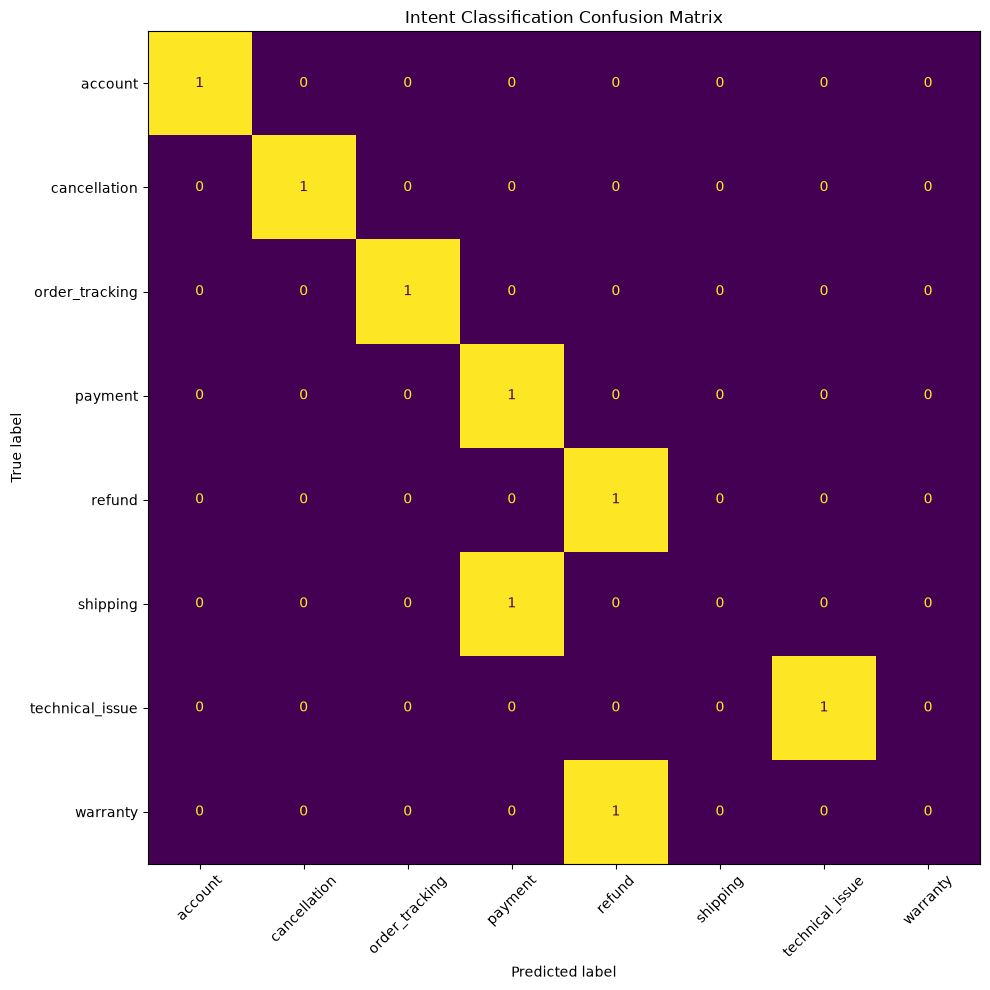

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45,
    colorbar=False
)

plt.title("Intent Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
def predict_intent(query: str):
    query_clean = clean_text(query)
    
    query_vector = tfidf.transform([query_clean])
    
    prediction = model.predict(query_vector)[0]
    
    probabilities = model.predict_proba(query_vector)[0]
    
    confidence = probabilities.max()
    
    return prediction, confidence

In [14]:
queries = [
    "I want to return my laptop",
    "Where is my shipment?",
    "My payment failed",
    "My device is getting very hot",
    "I forgot my password",
    "Can I cancel my order?"
]

for query in queries:
    intent, confidence = predict_intent(query)
    
    print(
        f"Query: {query}\n"
        f"Intent: {intent}\n"
        f"Confidence: {confidence:.2f}\n"
        + "-" * 50
    )

Query: I want to return my laptop
Intent: refund
Confidence: 0.19
--------------------------------------------------
Query: Where is my shipment?
Intent: order_tracking
Confidence: 0.27
--------------------------------------------------
Query: My payment failed
Intent: payment
Confidence: 0.33
--------------------------------------------------
Query: My device is getting very hot
Intent: technical_issue
Confidence: 0.34
--------------------------------------------------
Query: I forgot my password
Intent: account
Confidence: 0.38
--------------------------------------------------
Query: Can I cancel my order?
Intent: cancellation
Confidence: 0.40
--------------------------------------------------


In [15]:
import pickle

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

with open(
    MODEL_DIR / "intent_classifier.pkl",
    "wb"
) as f:
    pickle.dump(model, f)

with open(
    MODEL_DIR / "tfidf_vectorizer.pkl",
    "wb"
) as f:
    pickle.dump(tfidf, f)

print("Model saved successfully.")

Model saved successfully.
